# LFAST ETC quick start

LFAST is an array of small telescopes: nominally 20 units of 0.726 m at Kitt Peak, each feeding
a fiber, with the fibers merged into one spectrograph input. `lfast_etc` answers the two
questions every observer asks of such a system. How long do I need to expose to reach a given
signal-to-noise ratio (SNR) on this target, and what SNR do I get in a given time?

Two spectrographs are modelled: the WIYN Bench (visible; the preset used below is the R ~ 1800
sample configuration) and CSHELL (1.08 to 1.75 um, R = 18,000 to 43,000). The throughput
model follows Choi et al. (2026, SPIE 14147). The test suite reproduces the reference LFAST ETC
notebook of 2026-10-12 to one part in a million, so the numbers here are those of the reference
calculation.

After this notebook you will be able to build an ETC for any preset and array size, define a
target, read exposure times and SNRs off the result object, see which noise term limits you, and
plot what the extracted spectrum would look like.

## One idea to hold on to: everything is per resolution element

The spectrum is cut into bins one resolution element (resel) wide, $\delta\lambda = \lambda/R$.
In each bin the star delivers $N_*$ electrons per second (summed over the whole array), the sky
delivers $N_{sky}$ electrons per second per pixel, and the resel is spread over $n_{pix}$ detector
pixels (2.2 for the Bench, 2.5 for CSHELL). With dark current $D$, read noise $RN$ and a total
exposure $t$ split into $n_{exp}$ reads, the SNR per resel is (Howell 2006)

$$\mathrm{SNR} = \frac{N_* t}{\sqrt{N_* t + n_{pix}(N_{sky} + D)\,t + n_{pix}\, n_{exp}\, RN^2}}.$$

Survey papers often quote SNR per pixel. In the photon-limited regime that is lower by about
$\sqrt{n_{pix}}$, so SNR 30 per resel is roughly SNR 20 per pixel on the Bench. Keep that
conversion in mind when you compare with the literature.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

## Build an ETC

An `LFASTETC` is an instrument preset plus a telescope array plus a sky model. The presets are
TOML files inside the package; `list_instruments()` shows what ships. Printing the object tells
you what you built: resolving power, bandpass, pixels per resel, detector numbers, the array,
and the sky table.

In [2]:
print(list_instruments())
etc = LFASTETC("bench_r1800", n_telescopes=20)
etc

['bench_1200_28p7_o1', 'bench_1200_28p7_o2', 'bench_316_63p4_o9', 'bench_316_7p0_o1', 'bench_316_7p0_o2', 'bench_3300vph_o1', 'bench_400_4p2_o1', 'bench_600_13p9_o1', 'bench_600_13p9_o2', 'bench_740vph_o1', 'bench_740vph_o2', 'bench_860_30p9_o1', 'bench_860_30p9_o2', 'bench_860_30p9_o3', 'bench_r1800', 'cshell_r18000', 'cshell_r21500', 'cshell_r43000']


LFASTETC(bench_r1800: R=1800, 412-686 nm, 2.2x2.2 pix/resel (tophat), S_opt=0.3, slit=1.0, RN=3.7 e-, dark=0.0003 e-/s/pix | 20 x 0.726 m telescopes (total area 8.28 m^2, 3.2 m equivalent), 18um fiber (1.48" on sky), combine=fiber, 1 input(s) | SkyCalc table skytable_secz1.3.fits x 1, 918 bins)

The grid has one point per resel. Here that is about 900 bins between 412 and 686 nm. The preset
stops at 686 nm because the telescope throughput curve has a zero at the 687 nm O$_2$ band.

## Where the photons go: throughput

$K_{opt}$ is the end-to-end telescope throughput for a point source, and it already contains the
fiber injection efficiency $\eta_{fib}$ and the atmospheric extinction at the reference airmass
(that is how Choi et al. define it). The sky fills the fiber uniformly and pays no injection loss,
so it sees $K_{opt}/\eta_{fib}$. The spectrograph efficiency and the detector QE are flat
placeholders in the presets. The black curve is the product of everything, and it is low: a few
percent of the photons that hit the primary mirrors end up as detected electrons.

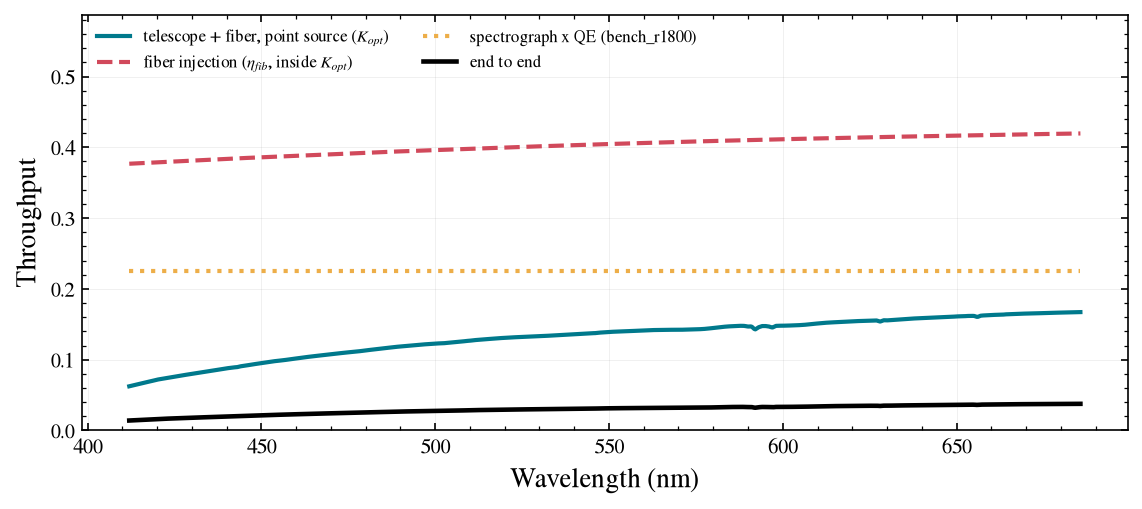

In [3]:
etc.plot_throughput();

## Define a source

A `Source` is a spectral shape plus one magnitude in one band. The magnitude sets the absolute
scale; the shape comes from a blackbody, a power law, a flat spectrum or your own arrays. You can
add Gaussian lines. They are averaged over each resel so the equivalent width is preserved: a
0.05 nm wide H$\alpha$ line with a 30% core, placed on a 0.36 nm resel, appears as a resel-wide
dip of about 10%. The magnitude you gave stays the continuum magnitude.

blackbody 5800 K, V=15.00 (Vega) | synthetic J = 13.85


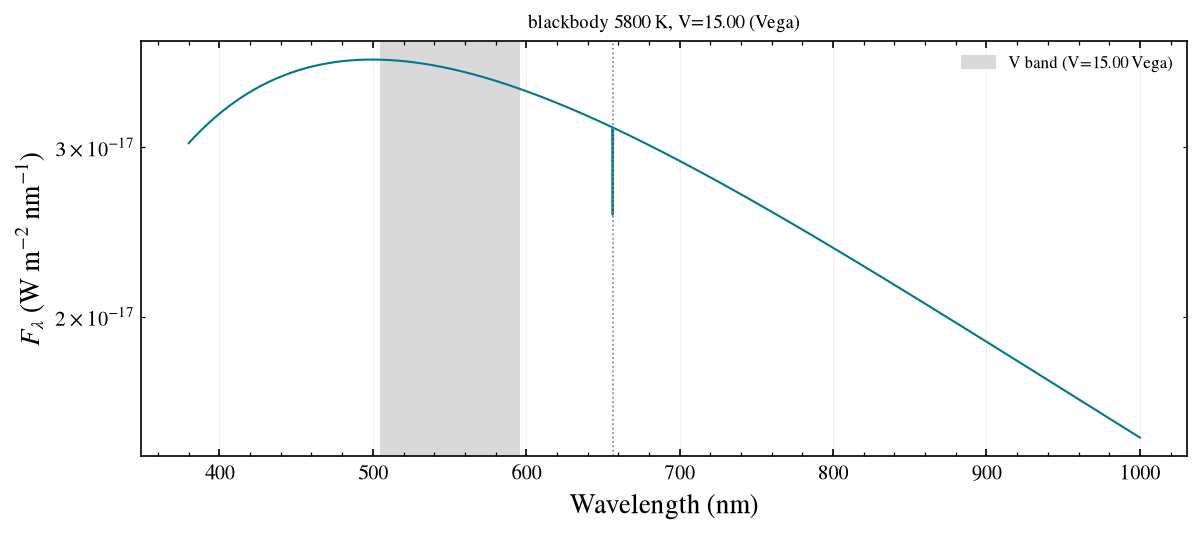

In [4]:
src = Source.blackbody(5800, mag=15, band="V").add_line(656.3, depth=0.3, sigma_nm=0.05)
print(src.describe(), "| synthetic J =", round(src.magnitude("J"), 2))
src.plot(wavelength_nm=np.linspace(380, 1000, 2000));

The shaded box is the normalising band. The synthetic J magnitude comes from integrating the same
SED over the J box band, which is how you get a magnitude in another band for a target you only
know in one.

## Exposure time to reach a target SNR

`exptime` returns an `ETCResult` with one value per bin. The plot shows the total exposure time
needed for SNR 50 per resel at each wavelength. Time rises steeply to the blue because both the
throughput and this star's SED fall there. The H$\alpha$ line shows up as a spike: fewer photons
in the line, more time needed.

{'snr': {10: 50.0, 50: 50.0, 90: 50.0},
 'exptime': {10: 232.31457754420978,
  50: 366.6287272760122,
  90: 937.6623892976786},
 'saturated_fraction': 0.0,
 'below_min_exptime_fraction': 0.0,
 'n_bins': 918}

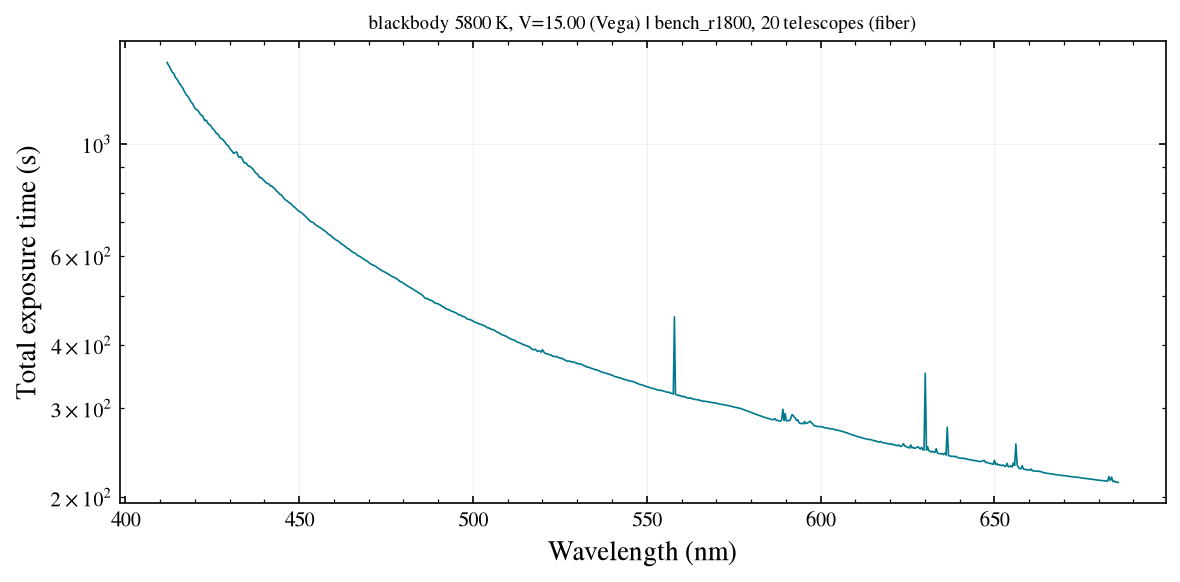

In [5]:
res = etc.exptime(src, snr=50)
res.plot()
res.summary()

`summary()` gives the 10th, 50th and 90th percentiles over the band. The median is the number to
quote if you need one exposure time for the whole spectrum. Pick one wavelength with `at`, or
export every column to an astropy table (`to_table().write("spectrum.csv")` for a file).

In [6]:
print(res.at(550.0))
res.to_table()[:5]

{'snr': 50.0, 'exptime': 331.36078361189647, 'n_star': 7.942802011508905, 'n_sky_pix': 0.044989844509745296, 'peak_e_per_pixel': 674.8966580038698}


wavelength,delta_lambda,snr,exptime,n_star,n_sky_pix,peak_e_per_pixel,saturated,below_min_exptime
float64,float64,float64,float64,float64,float64,float64,bool,bool
412.0,0.2288888888888889,50.0,1450.2439374133507,1.8545242059452185,0.019306117322110915,705.4123600050652,False,False
412.22888888888895,0.22901604938271608,50.0,1439.8909252990438,1.8653668784487003,0.0188549832853783,703.4879816866863,False,False
412.45790493827167,0.22914328052126204,50.0,1431.7650026213837,1.876241701886179,0.019032063876908173,703.7096201166241,False,False
412.68704821879294,0.22927058234377384,50.0,1422.846719842885,1.8871487171217074,0.01895078366782017,703.0593458843271,False,False
412.9163188011368,0.22939795488952044,50.0,1413.5408773733343,1.8980879649452478,0.018725631345830836,701.9354953390654,False,False


## SNR for a fixed exposure time

The inverse question. The dashed line marks SNR 50 so you can see where the 600 s exposure
reaches the target set above.

{10: 39.73707737886871, 50: 64.26208963438968, 90: 80.95568653591539}

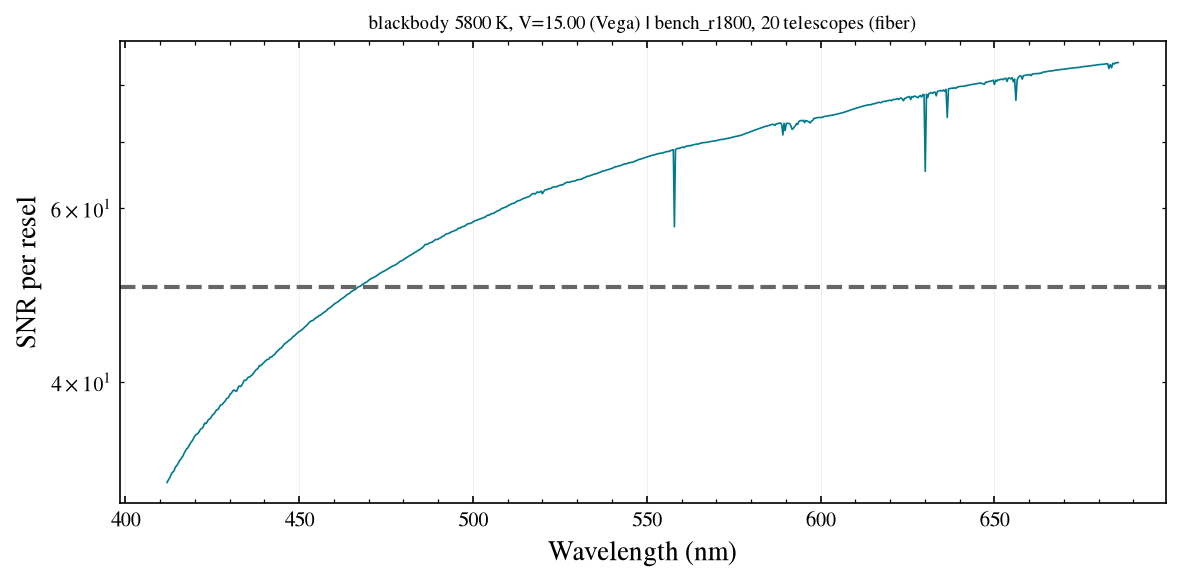

In [7]:
res = etc.snr(src, exptime=600)
ax = res.plot()
ax.axhline(50, color='0.4', ls='--')
res.summary()['snr']

## Which noise term limits you?

Two views of the same budget. The rates plot shows star, sky and dark electrons per pixel per
second; the noise-budget plot shows the fraction of the variance each term contributes for this
exposure. For a V = 15 star in 600 s the star dominates almost everywhere and the sky takes over
only at the bright airglow lines. Go three magnitudes fainter and the picture changes (try it).

The bundled sky table is grey time: the moon is up, 45 degrees from the target, and scattered
moonlight is about 60% of the visible sky. Faint-end results are therefore pessimistic by about
0.3 to 0.5 mag for dark time. Notebook 02 shows a crude dark-time scaling.

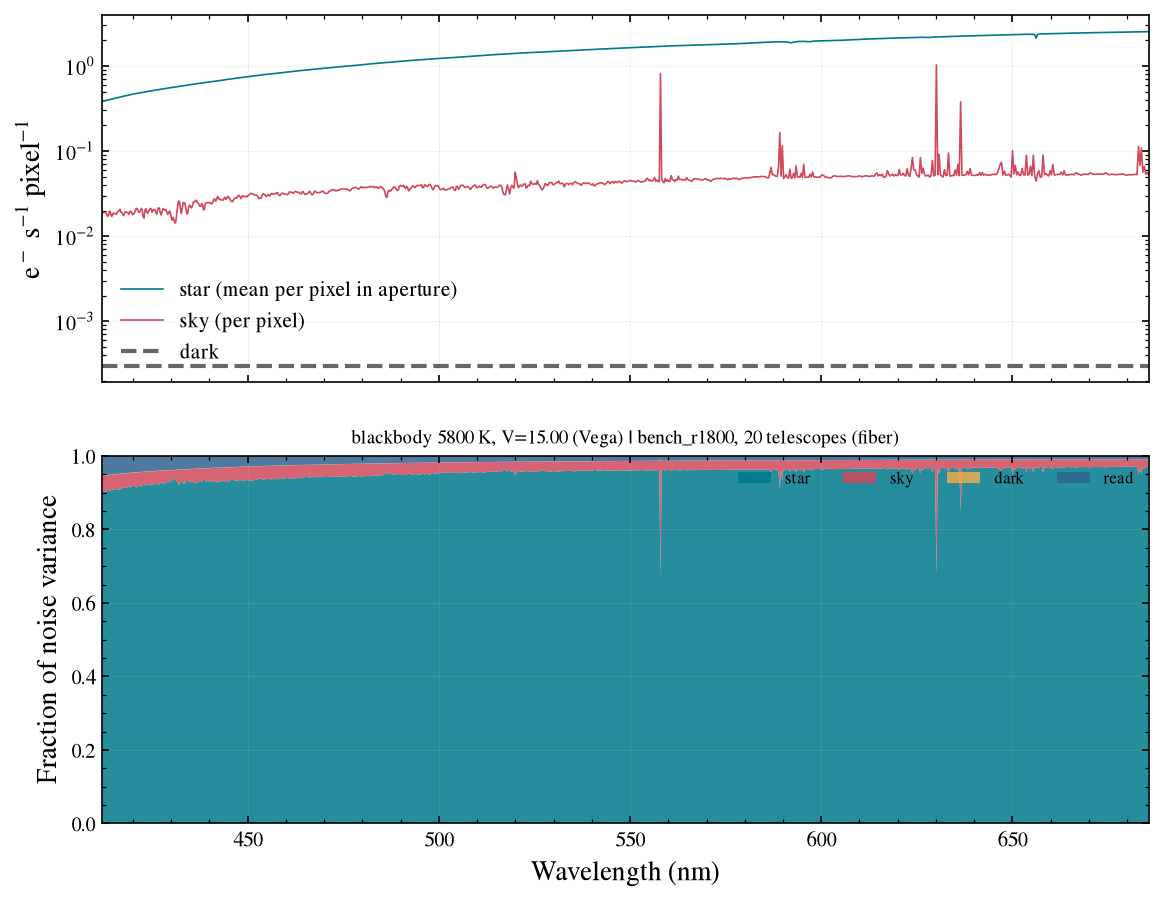

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
res.plot_rates(ax=axes[0])
res.plot_noise_budget(ax=axes[1])
axes[0].set_xlabel('');

## What the spectrum would look like

`simulate` draws one realisation of the extracted spectrum with the per-resel SNR of the result,
and `plot_spectrum` overlays it on the noiseless signal. The H$\alpha$ dip is clearly detected at
this SNR. This is the plot to show when someone asks whether a feature will be visible.

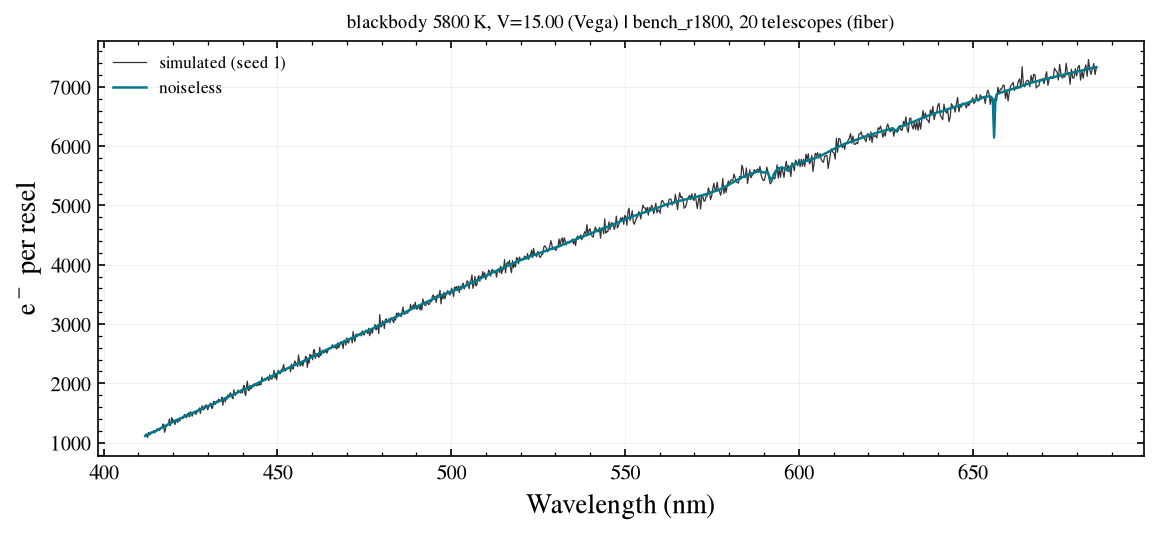

In [9]:
res.plot_spectrum(seed=1);

## The sky

Sky surface brightness per resel on the ETC grid, in AB magnitudes per square arcsecond (left
axis, brighter is up), with the sky electron rate per pixel in the 18 um fiber in grey. Around
550 nm the grey-time sky is about 20.3 mag per square arcsecond; dark Kitt Peak is about a
magnitude fainter. The spikes are airglow lines.

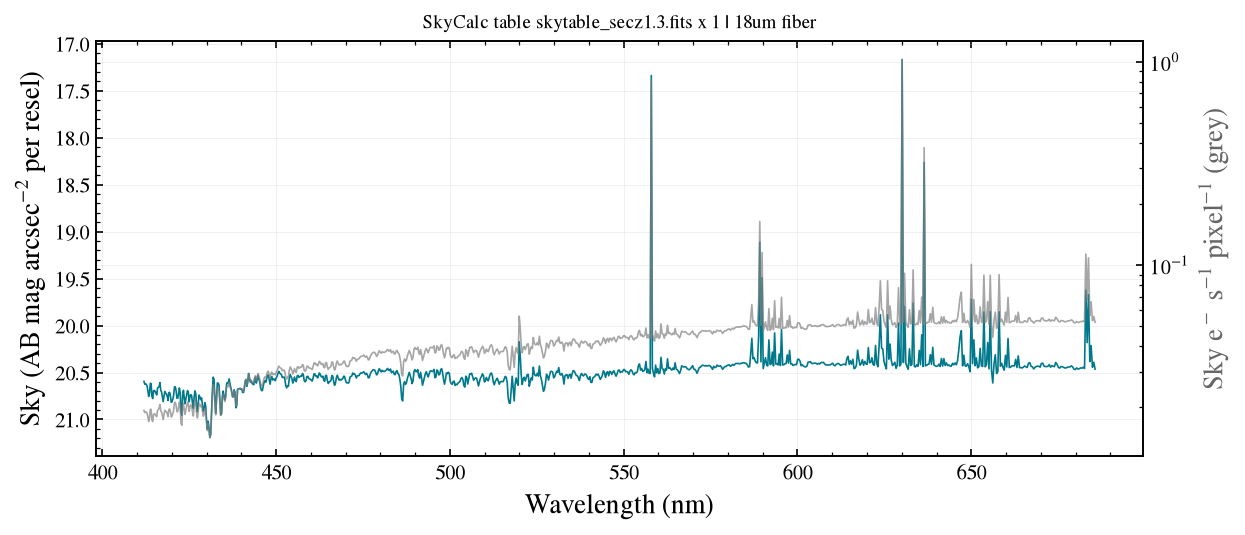

In [10]:
etc.plot_sky();

## Switching instruments and overriding parameters

CSHELL is an echelle with a small free spectral range, about 2.5e-3 of the wavelength, so one
setting covers about 40 A at 1.55 um. Restrict the grid to the setting you care about. Any
instrument field can be overridden through `Instrument.from_preset(name, **overrides)` or
`instrument.replace(...)`; the example lowers the read noise to see how much it matters for a
bright K star in 300 s.

In [11]:
cshell = LFASTETC("cshell_r18000", wavelength_min_nm=1550, wavelength_max_nm=1554)
kstar = Source.blackbody(4500, mag=9, band="H")
r = cshell.snr(kstar, exptime=300)
print("CSHELL R=18k, H=9 K star, 300 s: median SNR/resel =", round(float(np.nanmedian(r.snr)), 1),
      "| peak e-/pix =", int(np.nanmax(r.peak_e_per_pixel)), "| saturated:", bool(r.saturated.any()))

lowRN = Instrument.from_preset("cshell_r18000", read_noise=5.0)
r2 = LFASTETC(lowRN, wavelength_min_nm=1550, wavelength_max_nm=1554).snr(kstar, exptime=300)
print("same with RN = 5 e-:", round(float(np.nanmedian(r2.snr)), 1))

CSHELL R=18k, H=9 K star, 300 s: median SNR/resel = 38.4 | peak e-/pix = 530 | saturated: False
same with RN = 5 e-: 58.0


## Scaling the array

The number of telescopes is an ordinary parameter. With the 18 um fibers every telescope feeds the
same spectrograph input (`combine="fiber"`): signal and sky per pixel grow with $N$ while the
detector noise is paid once. The 50 um fiber does not go through the combiner, so each telescope
produces its own spectrum that is co-added afterwards (`combine="independent"`), and the SNR
grows as $\sqrt{N}$. For a faint star the fiber mode wins once read noise matters.

In [12]:
faint = Source.blackbody(5800, mag=19, band="V")
for n in (1, 5, 20, 50):
    for fiber in ("18um", "50um"):
        e = LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=n, fiber=fiber))
        t = e.exptime(faint, snr=20)
        print(f"N={n:3d} {fiber}: median t(SNR=20) = {np.nanmedian(t.exptime)/60:7.1f} min  [{e.telescope.combine}]")

N=  1 18um: median t(SNR=20) =  1716.0 min  [fiber]
N=  1 50um: median t(SNR=20) =  1677.9 min  [independent]
N=  5 18um: median t(SNR=20) =   324.6 min  [fiber]
N=  5 50um: median t(SNR=20) =   343.5 min  [independent]
N= 20 18um: median t(SNR=20) =    80.3 min  [fiber]
N= 20 50um: median t(SNR=20) =    93.0 min  [independent]
N= 50 18um: median t(SNR=20) =    34.2 min  [fiber]
N= 50 50um: median t(SNR=20) =    42.2 min  [independent]


## Your own spectrum

Any `(wavelength_nm, flux)` pair works. `flux_unit="flam"` means the array is proportional to
$F_\lambda$ in whatever unit; the magnitude sets the scale. Use `"fnu"` for an $F_\nu$ array and
`"W/m2/nm"` for an absolute spectrum, in which case the magnitude is derived rather than given.

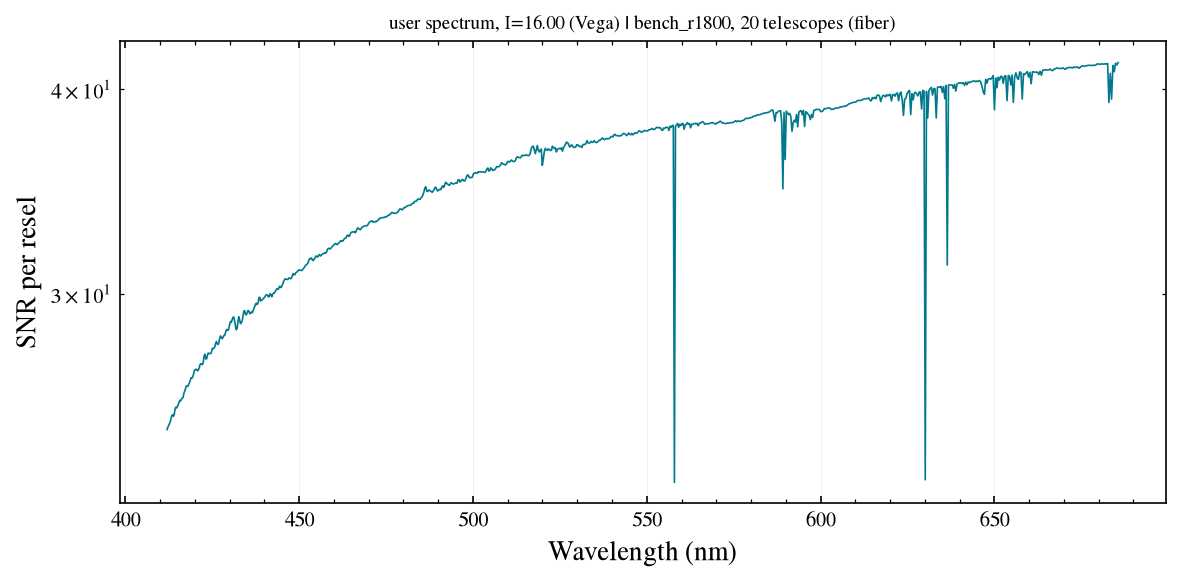

In [13]:
wl = np.linspace(380, 1800, 3000)
flux = wl**-2 * (1 + 0.5*np.exp(-0.5*((wl-850)/20)**2))   # F_nu-flat continuum with a bump
user = Source.from_arrays(wl, flux, flux_unit="flam", mag=16, band="I")
r = LFASTETC("bench_r1800").snr(user, 900)
r.plot();

## Check yourself

The round trip below must close: the SNR computed for the exposure times that `exptime` returned
has to be the target SNR in every bin. The second check is the $\sqrt{N}$ law for independent
spectra. If either fails, something in your installation is off.

In [14]:
t = etc.exptime(src, snr=50)
back = etc.snr(src, exptime=t.exptime)
assert np.allclose(back.snr[np.isfinite(back.snr)], 50, rtol=1e-8)

one = LFASTETC("bench_r1800", telescope=Telescope(1, combine="independent")).snr(src, 100).snr
twenty = LFASTETC("bench_r1800", telescope=Telescope(20, combine="independent")).snr(src, 100).snr
assert np.allclose(twenty, np.sqrt(20) * one, rtol=1e-10, equal_nan=True)
print("round trip and sqrt(N) scaling OK")

round trip and sqrt(N) scaling OK


## Things to try

* Change the star to `Source.blackbody(3500, mag=18, band="V")` and rerun the noise budget. At
  which wavelengths does the sky take over?
* Set `n_exp=10` in the SNR call. How much SNR does the extra read noise cost at V = 15, and at
  V = 19?
* Replace `"bench_r1800"` with `"bench_316_63p4_o9"` (the R ~ 23,000 H$\alpha$ mode). What
  happens to the exposure time for SNR 50 and why?